# 03 · Feature engineering — dari harga harian bersih ke tabel mingguan siap analisis

**Posisi di alur:** `01_eda` (kenali data) → `02_cleaning` (harga harian bersih) → **03 (notebook ini)** → `04`–`09` (Q1–Q6).

Notebook ini menjelaskan dua keluaran Tahap 3:
1. **Harga mingguan + fitur** (`src/features.py` → `data/interim/harga_mingguan.parquet`, `nasional_mingguan.parquet`,
   `kalender_mingguan.parquet`).
2. **Ongkos angkut per rute — ASUMSI, bukan data** (`src/logistics.py` → `data/reference/biaya_rute.csv`).

Pola proyek: **skrip mengerjakan, notebook menjelaskan.** Notebook memanggil `build()` dari kedua modul, lalu
**membuktikan hasilnya identik** dengan file yang dipakai analisis. Notebook ini tidak menulis file apa pun.
Semua parameter dibaca dari `config/config.yaml` (bagian `features`) dan `config/biaya_logistik.yaml`.

In [1]:
import io
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

from src import features as F, logistics as L  # noqa: E402
from src.analysis.common import (load_cfg, style, rp, pct, TEAL, BLUE, ORANGE, GRAY,  # noqa: E402
                                 KOMODITAS_URUT, LABEL_PENDEK)

cfg, lcfg = load_cfg()
f, c = cfg["features"], cfg["cleaning"]
INTERIM, REF = ROOT / cfg["paths"]["interim"], ROOT / cfg["paths"]["reference"]
style()
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]


def tgl(d) -> str:
    return f"{d.day} {BULAN[d.month - 1]} {d.year}"


def tampil(fig) -> None:
    """Tampilkan grafik di notebook (modul gaya memakai backend tanpa layar)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png")
    plt.close(fig)
    display(Image(data=buf.getvalue()))


print("Parameter features:", {k: v for k, v in f.items() if k != "seri_dikecualikan"})

Parameter features: {'frekuensi': 'W-FRI', 'agregasi_mingguan': {1: 'median', 2: 'terakhir', 3: 'terakhir', 4: 'terakhir'}, 'rolling_minggu': [4, 12], 'yoy_lag_minggu': 52, 'zscore_baseline_minggu': 52, 'zscore_min_minggu': 26, 'perubahan_lag_minggu': 4, 'zscore_return_baseline_minggu': 52, 'zscore_return_min_minggu': 26, 'idul_fitri_jendela': [-12, 4]}


## 1. Jalankan ulang Tahap 3 dan cek bahwa hasilnya sama dengan file yang dipakai analisis
Jika `build()` menghasilkan tabel yang sama persis dengan parquet di `data/interim/`, semua angka di notebook 04–09
benar-benar berasal dari kode yang dijelaskan di sini.

In [2]:
harian = pd.read_parquet(INTERIM / "harga_harian.parquet")
out = F.build(cfg)
for nama, berkas in [("mingguan", "harga_mingguan"), ("nasional", "nasional_mingguan"), ("kalender", "kalender_mingguan")]:
    tersimpan = pd.read_parquet(INTERIM / f"{berkas}.parquet")
    pd.testing.assert_frame_equal(out[nama].reset_index(drop=True), tersimpan.reset_index(drop=True), check_dtype=False)
    print(f"{berkas}.parquet: {len(tersimpan):,} baris x {tersimpan.shape[1]} kolom -> identik dengan build()")
w, nw, kal = out["mingguan"], out["nasional"], out["kalender"]
print(f"Harian masuk: {len(harian):,} baris | minggu: {w.minggu.nunique()} "
      f"({w.minggu_akhir.min():%Y-%m-%d} s/d {w.minggu_akhir.max():%Y-%m-%d}) | seri: {w[F.SERI].drop_duplicates().shape[0]}")

harga_mingguan.parquet: 107,087 baris x 36 kolom -> identik dengan build()
nasional_mingguan.parquet: 4,152 baris x 24 kolom -> identik dengan build()
kalender_mingguan.parquet: 173 baris x 9 kolom -> identik dengan build()
Harian masuk: 535,435 baris | minggu: 173 (2023-07-07 s/d 2026-10-23) | seri: 619


## 2. Kenapa mingguan, dan kenapa cara agregasinya berbeda per jenis pasar?
**Kenapa mingguan (Jumat sebagai akhir minggu, W-FRI):** PIHPS hanya mencatat hari kerja dan sampelnya kecil
(2 pasar × 2 pedagang per kota), sehingga harga harian berisik. Brief meminta analisis lead-lag dan musiman memakai data
mingguan. Minggu berakhir Jumat agar satu minggu = satu pekan kerja Senin–Jumat.

**Kenapa caranya berbeda:** `02_cleaning.ipynb` §7.2 menemukan bahwa hanya pasar tradisional yang benar-benar dicatat
setiap hari. Pedagang besar praktis hanya berubah pada hari Kamis, sedangkan hari lainnya adalah salinan harga
sebelumnya. Hanya pengamatan **nyata** yang dipakai; hari hasil isian celah (`is_imputed`) tidak ikut dihitung.

| Jenis pasar | Cara | Alasan |
|---|---|---|
| Pasar tradisional | median hari nyata | dicatat tiap hari; median meredam satu hari yang aneh |
| Pasar modern, pedagang besar, produsen | nilai nyata terakhir minggu itu | dicatat 1–2× seminggu atau sesekali |

**Bukti bahwa pilihan ini penting:** jika pedagang besar memakai median Senin–Jumat, berapa sering harga mingguannya
justru sama dengan harga **minggu lalu**? Yang dihitung hanya minggu ketika harga terakhir memang berubah dari minggu sebelumnya.

In [3]:
uji = {}
for cara in ("median", "terakhir"):
    agg = {jp: cara for jp in (1, 2, 3, 4)}
    uji[cara] = F.weekly_aggregate(harian, agg, F.SERI, c["minggu_min_hari_nyata"], f["frekuensi"]).harga
b = F.weekly_aggregate(harian, {jp: "terakhir" for jp in (1, 2, 3, 4)}, F.SERI, c["minggu_min_hari_nyata"], f["frekuensi"])
b = b.assign(med=uji["median"].to_numpy(), akhir=uji["terakhir"].to_numpy())
b["akhir_lalu"] = b.groupby(F.SERI).akhir.shift(1)
b = b[b.med.notna() & b.akhir.notna() & b.akhir_lalu.notna() & (b.akhir != b.akhir_lalu)]
nama_jp = harian.drop_duplicates("jenis_pasar_id").set_index("jenis_pasar_id").jenis_pasar
tertinggal = (b.assign(sama_minggu_lalu=b.med == b.akhir_lalu, sama_minggu_ini=b.med == b.akhir)
                .groupby("jenis_pasar_id")[["sama_minggu_lalu", "sama_minggu_ini"]].mean().mul(100).round(1))
tertinggal.index = tertinggal.index.map(nama_jp)
tertinggal.columns = ["median = harga minggu LALU (%)", "median = harga minggu ini (%)"]
tertinggal

,median = harga minggu LALU (%),median = harga minggu ini (%)
jenis_pasar_id,,
Pasar Tradisional,9.7,40.1
Pasar Modern,2.0,85.1
Pedagang Besar,81.7,8.4
Produsen,38.8,59.5


In [4]:
pb_lag = tertinggal.loc["Pedagang Besar", "median = harga minggu LALU (%)"]
display(Markdown(f"> Untuk pedagang besar, median Senin–Jumat sama dengan harga minggu lalu pada **{pb_lag:.0f}%** minggu "
                 "ketika harga sebenarnya sudah berubah. Karena itu jenis pasar ini memakai nilai nyata terakhir; dengan median, "
                 "selisih harga antar kota (Q2) dan tambahan harga di tiap tingkat (Q5) akan tertinggal satu minggu."))

> Untuk pedagang besar, median Senin–Jumat sama dengan harga minggu lalu pada **82%** minggu ketika harga sebenarnya sudah berubah. Karena itu jenis pasar ini memakai nilai nyata terakhir; dengan median, selisih harga antar kota (Q2) dan tambahan harga di tiap tingkat (Q5) akan tertinggal satu minggu.

### Contoh: harian vs mingguan (6 bulan terakhir)

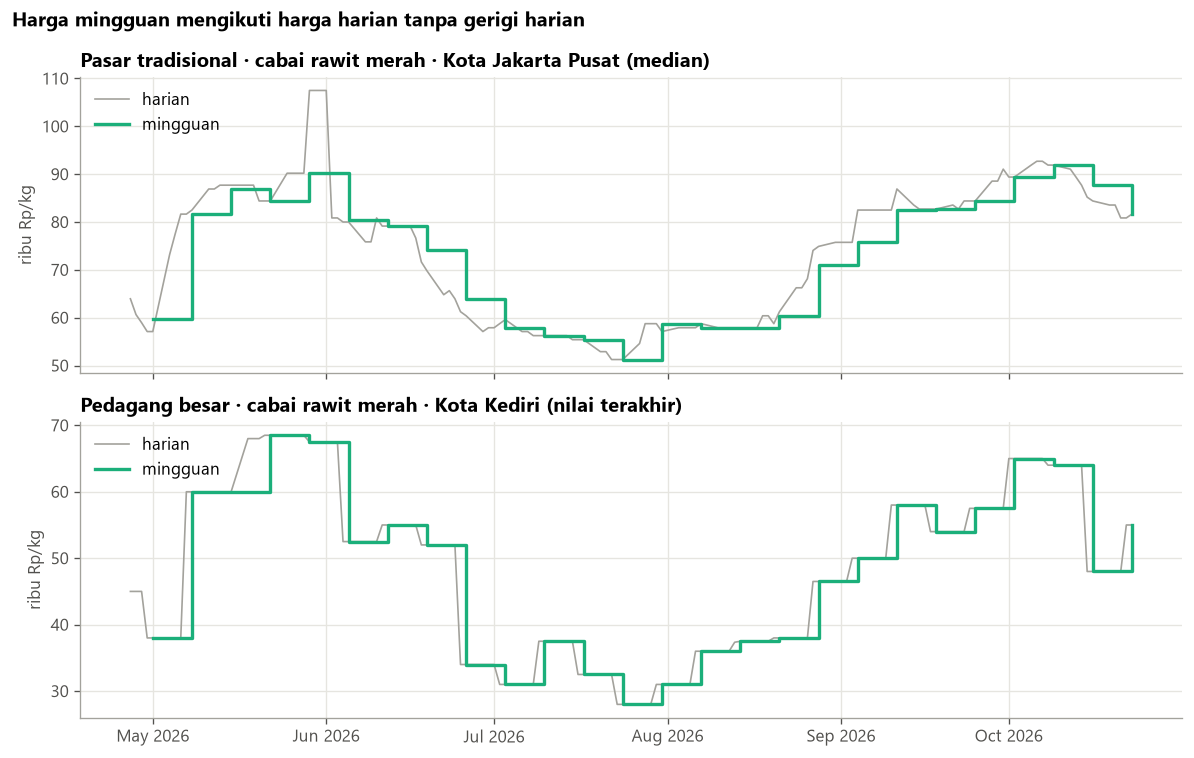

In [5]:
akhir = harian.tanggal.max()
contoh = [(1, "com_16", 34, "Pasar tradisional · cabai rawit merah · Kota Jakarta Pusat (median)"),
          (3, "com_16", 44, "Pedagang besar · cabai rawit merah · Kota Kediri (nilai terakhir)")]
fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
for ax, (jp, kom, kota, judul) in zip(axes, contoh):
    d = harian[(harian.jenis_pasar_id == jp) & (harian.komoditas_id == kom) & (harian.kota_id == kota)
               & (harian.tanggal > akhir - pd.Timedelta(days=182))]
    m = w[(w.jenis_pasar_id == jp) & (w.komoditas_id == kom) & (w.kota_id == kota)
          & (w.minggu_akhir > akhir - pd.Timedelta(days=182))]
    ax.plot(d.tanggal, d.harga_bersih / 1000, color=GRAY, lw=1, label="harian")
    ax.step(m.minggu_akhir, m.harga / 1000, where="post", color=TEAL, lw=2, label="mingguan")
    ax.set_title(judul)
    ax.set_ylabel("ribu Rp/kg")
    ax.legend(loc="upper left", frameon=False)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Harga mingguan mengikuti harga harian tanpa gerigi harian", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
tampil(fig)

### Kelengkapan per jenis pasar (seri yang dipakai)

In [6]:
pakai = w[~w.is_seri_dikecualikan]
leng = pakai.groupby("jenis_pasar").agg(
    seri=("kota_id", lambda s: 0), metode=("metode", "first"),
    minggu_berharga_pct=("harga", lambda s: round(s.notna().mean() * 100, 1)),
    minggu_tipis_pct=("minggu_tipis", lambda s: round(s.mean() * 100, 1)),
    rata_hari_nyata=("n_hari_nyata", lambda s: round(s.mean(), 2)))
leng["seri"] = pakai.groupby("jenis_pasar")[F.SERI].apply(lambda d: d.drop_duplicates().shape[0])
leng

,seri,metode,minggu_berharga_pct,minggu_tipis_pct,rata_hari_nyata
jenis_pasar,,,,,
Pasar Modern,130,terakhir,98.7,1.3,4.44
Pasar Tradisional,207,median,98.8,2.3,4.57
Pedagang Besar,136,terakhir,98.8,1.2,4.57
Produsen,138,terakhir,98.1,1.9,4.53


`minggu_tipis` = pasar tradisional dengan < 3 hari nyata, atau jenis pasar lain tanpa satu pun hari nyata. Minggu tipis
tidak dibuang (masih ada harganya bila ada 1–2 hari nyata), tetapi analisis bisa menyaringnya.

## 3. Seri yang dikecualikan dari analisis
Seri ini tetap disimpan (penanda `is_seri_dikecualikan`), tetapi tidak dipakai di Q1–Q6. Alasannya dari audit Tahap 2.

In [7]:
ex = pd.DataFrame(f["seri_dikecualikan"])
nama = w.drop_duplicates(F.SERI).set_index(F.SERI)[["jenis_pasar", "kota", "kualitas"]]
ex.join(nama, on=F.SERI)[["jenis_pasar", "kota", "kualitas", "alasan"]]

,jenis_pasar,kota,kualitas,alasan
0,Pasar Tradisional,Kab. Jember,Cabai Merah Keriting,bolong 73% (baris hilang Des 2023-Mar 2026)
1,Pasar Modern,Kab. Banyuwangi,Cabai Rawit Merah,bolong 90%
2,Pasar Modern,Kab. Banyuwangi,Bawang Merah Ukuran Sedang,bolong 65%
3,Pasar Modern,Kab. Banyuwangi,Bawang Putih Ukuran Sedang,bolong 63%
4,Pasar Modern,Kab. Cilacap,Bawang Merah Ukuran Sedang,bolong 13% (2 bulan hilang)
5,Produsen,Kota Blitar,Daging Ayam Ras Segar,baru mulai Jan 2026
6,Pasar Modern,Kota Blitar,Cabai Merah Keriting,harga ~1/3 kota lain berbulan-bulan (dugaan pe...
7,Pasar Modern,Kota Blitar,Cabai Rawit Merah,harga ~1/3 kota lain berbulan-bulan (dugaan pe...


## 4. Fitur perubahan harga
Semua fitur dihitung **per seri** (kota × komoditas × jenis pasar) dari harga mingguan:

| Kolom | Arti | Dipakai di |
|---|---|---|
| `log_return`, `pct_wow` | perubahan vs minggu lalu | Q1 gejolak, Q3 penentu arah |
| `pct_4w` | perubahan vs 4 minggu lalu | Q6 definisi lonjakan |
| `pct_yoy` | perubahan vs 52 minggu lalu | Q6 tebakan "sama seperti tahun lalu", dashboard |
| `harga_ma4`, `harga_ma12` | rata-rata 4 / 12 minggu terakhir | dashboard (tren) |
| `vol_4`, `vol_12` | gejolak 4 / 12 minggu terakhir | dashboard |
| `zscore` | harga minggu ini vs rata-rata 52 minggu **sebelumnya** | dashboard ("jauh di atas kebiasaan") |
| `zscore_return` | kenaikan minggu ini vs kenaikan 52 minggu **sebelumnya** | Q6 aturan peringatan (> 2) |
| `selisih_nasional_rp / _pct` | vs rata-rata nasional jenis pasar yang sama | dashboard Ringkasan |
| `minggu_ke_idul_fitri` | −12 … +4, minggu 0 = minggu yang memuat Idulfitri | Q4, Q6 |

Contoh baris (pasar tradisional, cabai rawit merah, Kota Jakarta Pusat, 6 minggu terakhir):

In [8]:
kol = ["minggu_akhir", "harga", "n_hari_nyata", "pct_wow", "pct_4w", "pct_yoy", "harga_ma4", "vol_12", "zscore",
       "zscore_return", "harga_nasional", "selisih_nasional_pct"]
s = w[(w.jenis_pasar_id == 1) & (w.komoditas_id == "com_16") & (w.kota_id == 34)]
s[kol].tail(6).set_index("minggu_akhir").round(3)

,harga,n_hari_nyata,pct_wow,pct_4w,pct_yoy,harga_ma4,vol_12,zscore,zscore_return,harga_nasional,selisih_nasional_pct
minggu_akhir,,,,,,,,,,,
2026-09-18,82700.0,5,0.002,0.369,0.703,78012.5,0.080,0.499,-0.048,95050.0,-0.130
2026-09-25,84400.0,5,0.021,0.187,0.769,81337.5,0.070,0.556,0.072,95850.0,-0.119
2026-10-02,89400.0,5,0.059,0.180,0.781,84750.0,0.068,0.775,0.331,100550.0,-0.111
2026-10-09,91900.0,5,0.028,0.114,0.764,87100.0,0.066,0.868,0.117,102000.0,-0.099
2026-10-16,87700.0,5,-0.046,0.060,0.775,88350.0,0.061,0.624,-0.409,104500.0,-0.161
2026-10-23,81650.0,5,-0.069,-0.033,0.773,87662.5,0.062,0.288,-0.586,103250.0,-0.209


### Bukti tanpa "mengintip masa depan"
Peringatan dini (Q6) hanya jujur jika fitur minggu *t* dihitung dari data sampai minggu *t*. Uji: hitung fitur dari
seri yang **dipotong** di minggu *t*, lalu bandingkan dengan hasil dari seri lengkap. Jika ada fitur yang memakai data
sesudah *t*, nilainya akan berbeda. Diuji untuk setiap minggu pada seri contoh.

In [9]:
fitur = ["log_return", "pct_wow", "pct_4w", "pct_yoy", "harga_ma4", "harga_ma12", "vol_4", "vol_12", "zscore", "zscore_return"]
dasar = s[F.SERI + ["minggu", "harga"]].reset_index(drop=True)
penuh = F.add_series_features(dasar, f).reset_index(drop=True)
selisih_maks, kosong_beda = 0.0, 0
for t in range(1, len(dasar)):
    potong = F.add_series_features(dasar.iloc[: t + 1], f).reset_index(drop=True)
    a, b_ = penuh.loc[t, fitur].astype(float), potong.loc[t, fitur].astype(float)
    kosong_beda += int((a.isna() != b_.isna()).sum())
    selisih_maks = max(selisih_maks, float(np.nan_to_num((a - b_).abs().max())))
print(f"Diuji {len(dasar) - 1} titik potong x {len(fitur)} fitur: selisih terbesar = {selisih_maks:.2e}, "
      f"nilai kosong yang berbeda = {kosong_beda}")

Diuji 172 titik potong x 10 fitur: selisih terbesar = 0.00e+00, nilai kosong yang berbeda = 0


### Fitur peringatan: kenaikan mingguan dibanding kebiasaan

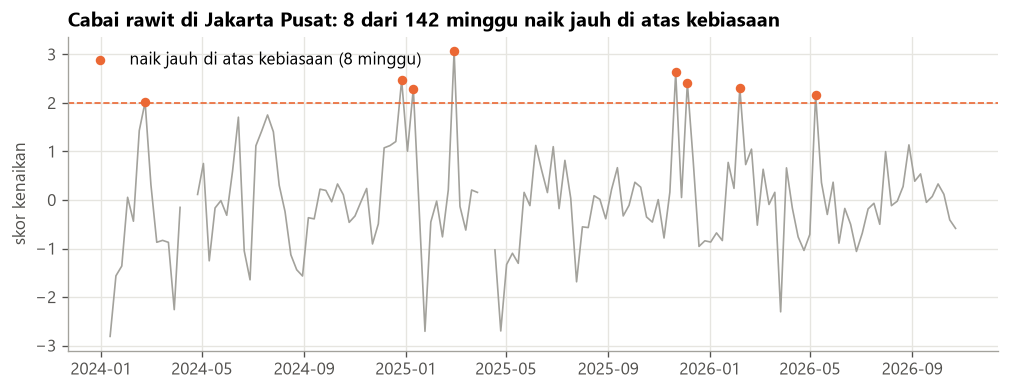

Seluruh pasar tradisional: 3.1% seri-minggu dengan skor kenaikan > 2


In [10]:
ambang = cfg["analisis"]["q6_peringatan"]["ambang_zscore_kenaikan"]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(s.minggu_akhir, s.zscore_return, color=GRAY, lw=1)
atas = s[s.zscore_return > ambang]
ax.scatter(atas.minggu_akhir, atas.zscore_return, color=ORANGE, s=22, zorder=3,
           label=f"naik jauh di atas kebiasaan ({len(atas)} minggu)")
ax.axhline(ambang, color=ORANGE, lw=1, ls="--")
ax.set_ylabel("skor kenaikan")
ax.legend(loc="upper left", frameon=False)
ax.set_title(f"Cabai rawit di Jakarta Pusat: {len(atas)} dari {s.zscore_return.notna().sum()} minggu "
             "naik jauh di atas kebiasaan")
tampil(fig)
porsi_z = (pakai[pakai.jenis_pasar_id == 1].zscore_return > ambang).mean()
print(f"Seluruh pasar tradisional: {porsi_z:.1%} seri-minggu dengan skor kenaikan > {ambang:g}")

## 5. Selisih dengan rata-rata nasional
Rata-rata nasional dihitung dengan cara agregasi yang sama (pasar tradisional = median, lainnya = terakhir). Positif =
lebih mahal dari rata-rata nasional. Tabel: median 52 minggu terakhir untuk kota tujuan distributor.

In [11]:
tujuan = list(cfg["wilayah"]["kota_tujuan"])
baru = pakai[(pakai.jenis_pasar_id == 1) & pakai.kota_id.isin(tujuan)
             & (pakai.minggu_akhir > pakai.minggu_akhir.max() - pd.Timedelta(weeks=52))]
tab_nas = baru.pivot_table(index="kualitas", columns="kota", values="selisih_nasional_pct", aggfunc="median")
tab_nas.reindex([k for k in KOMODITAS_URUT if k in tab_nas.index]).rename(index=LABEL_PENDEK).mul(100).round(1)

kota,Kota Bandung,Kota Jakarta Pusat,Kota Semarang,Kota Surabaya
kualitas,,,,
Cabai rawit merah,1.9,3.2,-26.6,-27.4
Cabai merah keriting,12.8,-2.1,-27.9,-26.3
Bawang merah,3.8,4.6,-17.5,-15.7
Bawang putih,10.2,10.2,-12.2,-13.7
Daging ayam ras,4.3,-0.2,-8.3,-6.4
Telur ayam ras,-8.8,-8.2,-12.2,-13.7


## 6. Kalender: minggu ke Idulfitri
Tanggal dari `data/reference/hari_besar.csv`, diverifikasi dari SKB libur nasional (bukan dari ingatan). Minggu 0 =
minggu Sabtu–Jumat yang memuat tanggal Idulfitri; jendela −12 … +4.

In [12]:
hb = pd.read_csv(REF / "hari_besar.csv", parse_dates=["tanggal", "libur_mulai", "libur_selesai"])
display(hb[hb.jenis == "idul_fitri"][["tanggal", "nama", "libur_mulai", "libur_selesai", "status_verifikasi"]])
jendela = kal.dropna(subset=["minggu_ke_idul_fitri"]).groupby("tahun_idul_fitri").agg(
    minggu_pertama=("minggu_akhir", "min"), minggu_terakhir=("minggu_akhir", "max"), jumlah_minggu=("minggu", "size"))
jendela

,tanggal,nama,libur_mulai,libur_selesai,status_verifikasi
3,2024-04-10,Idulfitri 1445 H,2024-04-08,2024-04-15,terverifikasi
7,2025-03-31,Idulfitri 1446 H,2025-03-31,2025-04-07,terverifikasi_sekunder
11,2026-03-21,Idulfitri 1447 H,2026-03-20,2026-03-24,terverifikasi


,minggu_pertama,minggu_terakhir,jumlah_minggu
tahun_idul_fitri,,,
2024,2024-01-19,2024-05-10,17
2025,2025-01-10,2025-05-02,17
2026,2026-01-02,2026-04-24,17


Seberapa banyak seri pasar tradisional yang punya harga pada minggu Lebaran (minggu 0)?

In [13]:
trad = pakai[pakai.jenis_pasar_id == 1]
lebaran = (trad[trad.minggu_ke_idul_fitri.isin([-1, 0, 1])]
           .pivot_table(index="tahun_idul_fitri", columns="minggu_ke_idul_fitri", values="harga",
                        aggfunc=lambda v: round(v.notna().mean() * 100, 1)))
lebaran.columns = [f"minggu {int(x):+d} (% seri berharga)" for x in lebaran.columns]
lebaran

,minggu -1 (% seri berharga),minggu +0 (% seri berharga),minggu +1 (% seri berharga)
tahun_idul_fitri,,,
2024,100.0,0.0,100.0
2025,100.0,0.0,100.0
2026,100.0,100.0,100.0


Minggu Lebaran bisa kosong karena pasar libur dan tidak ada pencatatan. Analisis Idulfitri (Q4) karena itu bersandar pada
minggu −8 … −1 dan +1 … +4, dan minggu kosong **tidak diisi**.

## 7. Ongkos angkut per rute — perkiraan, bukan data
Dipakai Q2 (rute pindah stok). Rumus (`config/biaya_logistik.yaml`, setiap angka disertai sumber atau label asumsi analis):

`ongkos angkut (Rp/kg) = (tarif truk/km × (1 + premi berpendingin) × jarak + tarif tol/km × jarak) / muatan efektif + bongkar-muat`

`biaya logistik (Rp/kg) = (ongkos angkut + susut % × harga di kota sumber) × pengali (0,5 / 1 / 1,5 / 2)`

Jarak jalan dari OpenStreetMap (OSRM). Tarif tol per km = nilai **terbesar** dari rute tol referensi (konservatif).

In [14]:
br, meta = L.build(cfg, lcfg)
tersimpan = pd.read_csv(REF / "biaya_rute.csv")
pd.testing.assert_frame_equal(br.reset_index(drop=True), tersimpan, check_dtype=False)
print(f"biaya_rute.csv: {len(br)} rute x komoditas -> identik dengan logistics.build()")
print("Tarif truk:", rp(lcfg["truk"]["tarif_per_km"]), "/km | tarif tol dipakai:", rp(meta["tarif_tol_per_km"]), "/km")
print("Tarif tol per rute referensi:", {k: rp(v) for k, v in meta["tol_detail"].items()})
asumsi = pd.DataFrame({
    "muatan efektif (kg)": {k: v["kg"] for k, v in lcfg["muatan_efektif_kg"].items()},
    "susut (% harga sumber)": {k: v * 100 for k, v in lcfg["penanganan"]["susut_pct"].items()},
    "premi berpendingin": {k: lcfg["premi_berpendingin"].get(k, lcfg["premi_berpendingin"].get("lainnya", 0.0))
                           for k in lcfg["muatan_efektif_kg"]}})
asumsi.index = asumsi.index.map(w.drop_duplicates("komoditas_id").set_index("komoditas_id").kualitas).map(LABEL_PENDEK)
asumsi

biaya_rute.csv: 32 rute x komoditas -> identik dengan logistics.build()
Tarif truk: Rp 6.000 /km | tarif tol dipakai: Rp 1.851 /km
Tarif tol per rute referensi: {'jakarta_surabaya_aptrindo': 'Rp 1.851', 'cikampek_kalikangkung_2025': 'Rp 1.774'}


,muatan efektif (kg),susut (% harga sumber),premi berpendingin
Cabai merah keriting,3000,5.0,0.0
Cabai rawit merah,3000,5.0,0.0
Bawang merah,4500,3.0,0.0
Bawang putih,4500,1.0,0.0
Telur ayam ras,4000,2.0,0.0
Daging ayam ras,3500,1.0,0.4


### Komponen biaya per rute (pengali 1×)

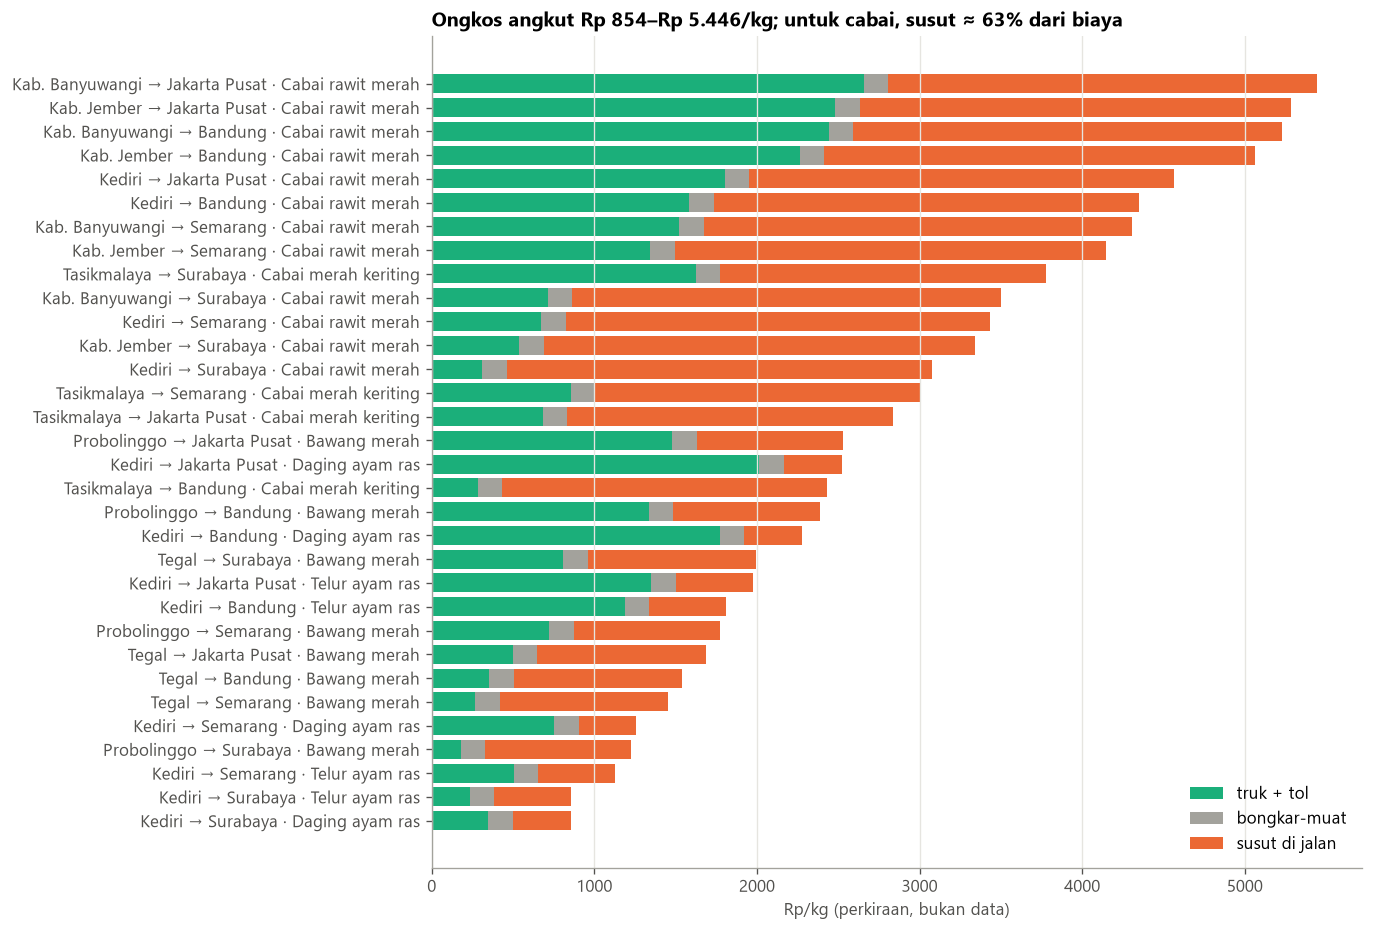

In [15]:
k = br.assign(rute=br.kota_sumber.str.replace("Kota ", "") + " → " + br.kota_tujuan.str.replace("Kota ", "")
              + " · " + br.kualitas.map(LABEL_PENDEK),
              truk_tol=(br.biaya_truk_rp + br.biaya_tol_rp) / br.muatan_efektif_kg)
k = k.sort_values("biaya_logistik_x1_rp_per_kg")
fig, ax = plt.subplots(figsize=(10, 9))
kiri = np.zeros(len(k))
for col, warna, label in [("truk_tol", TEAL, "truk + tol"), ("bongkar_muat_rp_per_kg", GRAY, "bongkar-muat"),
                          ("susut_rp_per_kg", ORANGE, "susut di jalan")]:
    ax.barh(k.rute, k[col], left=kiri, color=warna, label=label)
    kiri += k[col].to_numpy()
ax.set_xlabel("Rp/kg (perkiraan, bukan data)")
ax.legend(loc="lower right", frameon=False)
porsi_susut = (k.susut_rp_per_kg / k.biaya_logistik_x1_rp_per_kg)
cabai = porsi_susut[k.komoditas_id.isin(["com_14", "com_16"])].median()
ax.set_title(f"Ongkos angkut {rp(k.biaya_logistik_x1_rp_per_kg.min())}–{rp(k.biaya_logistik_x1_rp_per_kg.max())}/kg; "
             f"untuk cabai, susut ≈ {pct(cabai)} dari biaya")
ax.grid(axis="y", visible=False)
tampil(fig)

Susut dihitung dari harga di kota sumber, sehingga cabai yang mahal punya biaya susut besar meski truknya sama.
Di tabel di atas, susut memakai median harga pedagang besar 52 minggu terakhir; **di Q2 susut dihitung ulang setiap minggu**
dari harga sumber minggu itu (`src.logistics.biaya_logistik`).

### Cek kewajaran: dibanding margin perdagangan & pengangkutan BPS (MPP)
Jika ongkos angkut saja sudah melebihi seluruh margin perdagangan BPS untuk komoditas itu, asumsinya tidak masuk akal.

In [16]:
mpp = br.groupby("kualitas").agg(rute=("status_mpp", "size"), status=("status_mpp", lambda v: ", ".join(sorted(set(v)))),
                                 ongkos_per_mpp_min=("porsi_dari_mpp", "min"), ongkos_per_mpp_maks=("porsi_dari_mpp", "max"))
mpp.rename(index=LABEL_PENDEK)

,rute,status,ongkos_per_mpp_min,ongkos_per_mpp_maks
kualitas,,,,
Bawang merah,8,ok,0.03,0.14
Cabai merah keriting,4,ok,0.03,0.10
Cabai rawit merah,12,ok,0.02,0.12
Daging ayam ras,4,ok,0.06,0.25
Telur ayam ras,4,ok,0.08,0.31


`ok` = ongkos angkut ≤ 50% MPP. Bawang putih tidak punya rute karena tidak ada kota sumber bawang putih di config
(sebagian besar impor; BPS juga tidak menerbitkan MPP-nya). Detail sumber angka: `config/biaya_logistik.yaml` dan `docs/biaya_logistik_report.md`.

### Uji sensitivitas yang dibawa ke Q2
Karena semua angka di atas adalah perkiraan, Q2 mengulang hitungan dengan ongkos ×0,5, ×1, ×1,5, ×2. Rute hanya
direkomendasikan jika tetap untung pada ×1,5.

In [17]:
sens = br[[col for col in br.columns if col.startswith("biaya_logistik_x") and col.endswith("_rp_per_kg")]]
sens.columns = [col.replace("biaya_logistik_", "").replace("_rp_per_kg", "") for col in sens.columns]
sens = sens[sorted(sens.columns, key=lambda x: float(x[1:]))]
sens.describe().loc[["min", "50%", "max"]].round(0).rename(index={"50%": "median"})

,x0.5,x1,x1.5,x2
min,427.0,854.0,1281.0,1708.0
median,1263.0,2526.0,3788.0,5051.0
max,2723.0,5446.0,8169.0,10893.0


## 8. Ringkasan: fitur ini dipakai untuk menjawab apa?

| Pertanyaan | Fitur dari notebook ini |
|---|---|
| Q1 gejolak harga | harga mingguan pasar tradisional, `log_return` |
| Q2 rute pindah stok | harga mingguan pedagang besar (sumber) & tradisional (tujuan), ongkos angkut per rute + susut mingguan |
| Q3 kota penentu arah | `log_return` mingguan pasar tradisional |
| Q4 pola Idulfitri | harga mingguan + `minggu_ke_idul_fitri` |
| Q5 tambahan harga per tingkat | harga mingguan produsen, pedagang besar, pasar (diringkas bulanan di Q5) |
| Q6 peringatan dini | `pct_4w` (lonjakan), `zscore_return` (peringatan), `minggu_ke_idul_fitri`, `pct_yoy` (pembanding) |

### Temuan (bahasa dashboard)
Kalimat di bawah dihitung dari tabel di atas, bukan diketik tangan.

In [18]:
ada_trad = trad.harga.notna().mean()
susut_cabai = cabai
display(Markdown(
    f"**Data harga mingguan siap dipakai: {w.minggu.nunique()} minggu "
    f"({tgl(w.minggu_akhir.min())} – {tgl(w.minggu_akhir.max())}), "
    f"{pakai[F.SERI].drop_duplicates().shape[0]} seri harga dari {pakai.kota_id.nunique()} kota.**  \n"
    f"Pasar tradisional punya harga pada {pct(ada_trad)} minggu; minggu Lebaran yang libur dibiarkan kosong, tidak dikarang.  \n"
    f"Ongkos angkut (perkiraan, bukan data) {rp(br.biaya_logistik_x1_rp_per_kg.min())}–"
    f"{rp(br.biaya_logistik_x1_rp_per_kg.max())}/kg per rute; untuk cabai, sekitar {pct(susut_cabai)} dari biaya itu adalah "
    f"susut di jalan, bukan truk.  \n"
    "Tindakan: jangan memutuskan rute dari satu angka ongkos; pakai hasil Q2 yang sudah diuji dengan ongkos 1,5× dan 2×."))

**Data harga mingguan siap dipakai: 173 minggu (7 Jul 2023 – 23 Okt 2026), 611 seri harga dari 62 kota.**  
Pasar tradisional punya harga pada 99% minggu; minggu Lebaran yang libur dibiarkan kosong, tidak dikarang.  
Ongkos angkut (perkiraan, bukan data) Rp 854–Rp 5.446/kg per rute; untuk cabai, sekitar 63% dari biaya itu adalah susut di jalan, bukan truk.  
Tindakan: jangan memutuskan rute dari satu angka ongkos; pakai hasil Q2 yang sudah diuji dengan ongkos 1,5× dan 2×.